In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [54]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,PolynomialFeatures
from sklearn.linear_model import LinearRegression

In [55]:
data=load_diabetes()

In [56]:
data

{'data': array([[ 0.03807591,  0.05068012,  0.06169621, ..., -0.00259226,
          0.01990749, -0.01764613],
        [-0.00188202, -0.04464164, -0.05147406, ..., -0.03949338,
         -0.06833155, -0.09220405],
        [ 0.08529891,  0.05068012,  0.04445121, ..., -0.00259226,
          0.00286131, -0.02593034],
        ...,
        [ 0.04170844,  0.05068012, -0.01590626, ..., -0.01107952,
         -0.04688253,  0.01549073],
        [-0.04547248, -0.04464164,  0.03906215, ...,  0.02655962,
          0.04452873, -0.02593034],
        [-0.04547248, -0.04464164, -0.0730303 , ..., -0.03949338,
         -0.00422151,  0.00306441]], shape=(442, 10)),
 'target': array([151.,  75., 141., 206., 135.,  97., 138.,  63., 110., 310., 101.,
         69., 179., 185., 118., 171., 166., 144.,  97., 168.,  68.,  49.,
         68., 245., 184., 202., 137.,  85., 131., 283., 129.,  59., 341.,
         87.,  65., 102., 265., 276., 252.,  90., 100.,  55.,  61.,  92.,
        259.,  53., 190., 142.,  75., 142.

In [57]:
#map into dataframe format for better visualization
#data.data--2nd data is our variable name
x=pd.DataFrame(data.data,columns=data.feature_names)
y=data.target
x

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641
...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930


In [58]:
features=['bmi','bp','s5']
X=x[features]

In [59]:
X_train,X_test,Y_train,Y_test=train_test_split(X,y,test_size=0.2,random_state=2)

print(X_test)

          bmi        bp        s5
212  0.003494  0.035644 -0.000612
422  0.077863  0.052858  0.040673
67  -0.014828 -0.017135 -0.011897
89  -0.048241 -0.019442 -0.024795
390  0.069241  0.059744  0.103297
..        ...       ...       ...
129  0.016428  0.004658  0.038968
417  0.071397 -0.074527 -0.046883
332  0.104809  0.076958  0.057108
150  0.070319  0.025315 -0.019198
192 -0.030996  0.008101 -0.029526

[89 rows x 3 columns]


In [60]:
scaler=StandardScaler()
#fit funnction--computes mean and std dev of the data and stores it in scaler object
#X_train--used for computing mean and std dev
X_train=scaler.fit_transform(X_train)
#transform function--used to scale the data using mean and std dev computed in fit function
X_test=scaler.transform(X_test)

In [61]:
def costfunction(y_actual,y_predicted):
    m=len(y_actual)
    summ=np.sum((y_predicted-y_actual)**2)
    return (summ/(2*m))

In [ ]:
#polynomial regression
degree=range(1,7)
cost_values=[]
for deg in degree:
    poly=PolynomialFeatures(degree=deg,include_bias=False)
    x_train_poly=poly.fit_transform(X_train)
    x_test_poly=poly.transform(X_test)

    #scaling again the polynomial features that got created
    scaler = StandardScaler()
    X_train_poly = scaler.fit_transform(x_train_poly)
    X_test_poly = scaler.transform(x_test_poly)
    model=LinearRegression()
    model.fit(X_train_poly,Y_train)
    y_pred=model.predict(X_test_poly)

    cost=costfunction(Y_test,y_pred)
    cost_values.append(cost)

    print(f"Degree{deg}Cost={cost:.2f}")

Degree1Cost=1714.56
Degree2Cost=1796.08
Degree3Cost=1853.48
Degree4Cost=1905.11
Degree5Cost=1930.98
Degree6Cost=6535.52


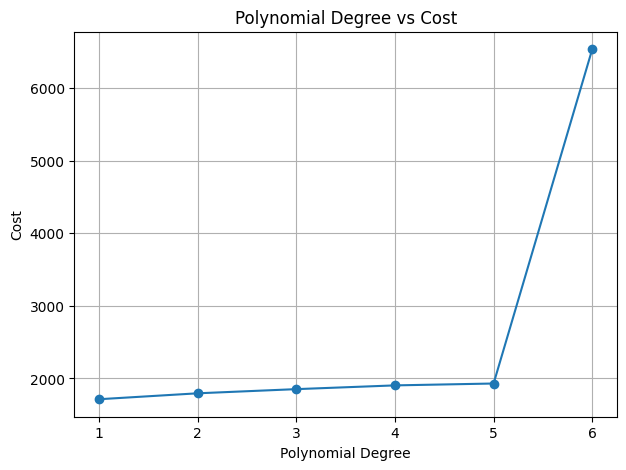

In [63]:
plt.figure(figsize=(7,5))
plt.plot(list(degree), cost_values, marker='o')
plt.xlabel("Polynomial Degree")
plt.ylabel("Cost")
plt.title("Polynomial Degree vs Cost")
plt.grid(True)
plt.show()